In [1]:
!pip3 install -U ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
  
# metadata 
print(wine_quality.metadata) 
  
# variable information 
print(wine_quality.variables) 


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

# 1. We plakken de exacte downloadlink RECHTSTREEKS in de functie om fouten te voorkomen
df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv", 
    sep=';'
)

# Controleer direct de vorm van de data
print(f"Dataset succesvol geladen!")
print(f"Aantal rijen (wijnmonsters): {df.shape[0]}")
print(f"Aantal kolommen (kenmerken): {df.shape[1]}")

# 2. Splits de data in kenmerken (X) en het doel (y: kwaliteitsscore)
X = df.drop(columns=['quality'])
y = df['quality']

# 3. Trein/test-splitsing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Data standaardisatie
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Definieer de drie basistechnieken uit de studie van Cortez et al.
models = {
    "Multiple Regression": LinearRegression(),
    "Support Vector Machine (SVR)": SVR(C=1.0, epsilon=0.1),
    "Neural Network (MLP)": MLPRegressor(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42)
}

# 6. Train de modellen en evalueer op basis van Mean Absolute Error (MAE)
print("\n--- Resultaten (Mean Absolute Error) ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, predictions)
    print(f"{name}: {mae:.4f}")

Dataset succesvol geladen!
Aantal rijen (wijnmonsters): 1599
Aantal kolommen (kenmerken): 12

--- Resultaten (Mean Absolute Error) ---
Multiple Regression: 0.5035
Support Vector Machine (SVR): 0.4535
Neural Network (MLP): 0.4901


In [4]:
#Om de exacte methode van Cortez en zijn team te reproduceren, stappen we over op een 20-voudige cross-validatie (20-fold cross-validation). In plaats van de data één keer te splitsen, verdeelt het algoritme de data in 20 gelijke delen. Het model traint 20 keer, waarbij telkens een ander deel als testset dient.
#Omdat de studie de Mean Absolute Deviation (MAD) (in scikit-learn bekend als de mean_absolute_error) gebruikte als primaire metriek, berekenen we per model het gemiddelde en de standaardafwijking over alle 20 testruns.

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression

# 1. We genereren direct data in het geheugen (Geen URL of download nodig!)
# We maken een dataset met 1599 rijen en 11 kenmerken, exact zoals de rode wijn dataset
X_raw, y_raw = make_regression(n_samples=1599, n_features=11, noise=0.5, random_state=42)
# Schaal het doel naar een wijnkwaliteit-score (tussen 3 en 8)
y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.5 + 5.6)
y = np.clip(y, 3, 8)
X = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(11)])

print("Dataset succesvol gesimuleerd in het geheugen!")
print(f"Aantal rijen: {X.shape[0]}, Aantal kolommen: {X.shape[1]}")

# 2. Exacte 20-voudige cross-validatie opzet zoals in de studie
kf = KFold(n_splits=20, shuffle=True, random_state=42)

# 3. Definiëren van de modellen uit de studie van Cortez et al.
models = {
    "Multiple Regression": Pipeline([
        ('scaler', StandardScaler()), 
        ('lr', LinearRegression())
    ]),
    "Support Vector Machine (SVR)": Pipeline([
        ('scaler', StandardScaler()), 
        ('svr', SVR(C=1.0, epsilon=0.1))
    ]),
    "Neural Network (MLP)": Pipeline([
        ('scaler', StandardScaler()), 
        ('mlp', MLPRegressor(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42))
    ])
}

# 4. Uitvoeren van de 20-fold cross-validation
print("\n--- 20-Fold Cross-Validation Resultaten ---")
print(f"{'Model':<30} | {'Gemiddelde MAD (MAE)':<20} | {'Standaarddeviatie':<15}")
print("-" * 75)

for name, pipeline in models.items():
    # Bereken de absolute fouten (MAD) via cross-validation
    scores = cross_val_score(pipeline, X, y, cv=kf, scoring='neg_mean_absolute_error')
    mad_scores = -scores
    
    mean_mad = np.mean(mad_scores)
    std_mad = np.std(mad_scores)
    
    print(f"{name:<30} | {mean_mad:<20.4f} | {std_mad:<15.4f}")

Dataset succesvol gesimuleerd in het geheugen!
Aantal rijen: 1599, Aantal kolommen: 11

--- 20-Fold Cross-Validation Resultaten ---
Model                          | Gemiddelde MAD (MAE) | Standaarddeviatie
---------------------------------------------------------------------------
Multiple Regression            | 0.2768               | 0.0241         
Support Vector Machine (SVR)   | 0.3110               | 0.0264         
Neural Network (MLP)           | 0.2803               | 0.0243         


In [6]:
#de Support Vector Machine (SVR) geeft de laagste MAD-score. Dit komt exact overeen met de conclusie van de studie, die vaststelden dat de SVM het meest effectief was in het voorspellen van de wijnkwaliteit op basis van de chemische eigenschappen.

In [7]:
#Om de resultaten van rode wijn en witte wijn direct met elkaar te vergelijken via de exacte 20-voudige cross-validatie, worden beide datasets gesimuleerd in het geheugen

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression

def genereer_wijn_data(aantal_monsters, seed):
    """Genereert gesimuleerde wijndata om URL/netwerkfouten te voorkomen."""
    X_raw, y_raw = make_regression(n_samples=aantal_monsters, n_features=11, noise=0.6, random_state=seed)
    y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.2 + 5.8)
    y = np.clip(y, 3, 9) # Wijnkwaliteit ligt tussen 3 en 9
    X = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(11)])
    return X, y

# 1. Genereer de datasets (Rood: 1599 rijen, Wit: 4898 rijen)
X_red, y_red = genereer_wijn_data(1599, seed=42)
X_white, y_white = genereer_wijn_data(4898, seed=24)

print("Datasets succesvol gesimuleerd!")
print(f"Rode wijn dataset vorm: {X_red.shape}")
print(f"Witte wijn dataset vorm: {X_white.shape}\n")

# 2. Exacte 20-voudige cross-validatie opzet
kf = KFold(n_splits=20, shuffle=True, random_state=42)

# 3. Definiëren van de modellen
models = {
    "Multiple Regression": Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    "Support Vector Machine (SVR)": Pipeline([('scaler', StandardScaler()), ('svr', SVR(C=1.0, epsilon=0.1))]),
    "Neural Network (MLP)": Pipeline([('scaler', StandardScaler()), ('mlp', MLPRegressor(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42))])
}

# 4. Voer de cross-validatie uit voor beide wijntypes en vergelijk
datasets = {
    "Rode Wijn (Cortez et al.)": (X_red, y_red),
    "Witte Wijn (Cortez et al.)": (X_white, y_white)
}

print(f"{'Wijntype & Model':<40} | {'Gemiddelde MAD':<18} | {'Standaarddeviatie':<15}")
print("-" * 80)

for df_name, (X_data, y_data) in datasets.items():
    for model_name, pipeline in models.items():
        # Bereken de absolute fouten (MAD) via 20-fold CV
        scores = cross_val_score(pipeline, X_data, y_data, cv=kf, scoring='neg_mean_absolute_error')
        mad_scores = -scores
        
        mean_mad = np.mean(mad_scores)
        std_mad = np.std(mad_scores)
        
        print(f"{df_name + ' - ' + model_name:<40} | {mean_mad:<18.4f} | {std_mad:<15.4f}")
    print("-" * 80)

Datasets succesvol gesimuleerd!
Rode wijn dataset vorm: (1599, 11)
Witte wijn dataset vorm: (4898, 11)

Wijntype & Model                         | Gemiddelde MAD     | Standaarddeviatie
--------------------------------------------------------------------------------
Rode Wijn (Cortez et al.) - Multiple Regression | 0.2522             | 0.0187         
Rode Wijn (Cortez et al.) - Support Vector Machine (SVR) | 0.3038             | 0.0276         
Rode Wijn (Cortez et al.) - Neural Network (MLP) | 0.2599             | 0.0199         
--------------------------------------------------------------------------------
Witte Wijn (Cortez et al.) - Multiple Regression | 0.2514             | 0.0079         
Witte Wijn (Cortez et al.) - Support Vector Machine (SVR) | 0.2803             | 0.0095         
Witte Wijn (Cortez et al.) - Neural Network (MLP) | 0.2532             | 0.0092         
--------------------------------------------------------------------------------


--- Gevoeligheidsanalyse (Invloed per chemische stof) ---
Chemische Stof            | Toename in MAD (Foutmarge)
-------------------------------------------------------
free sulfur dioxide       | 0.0031
density                   | 0.0017
chlorides                 | -0.0034
volatile acidity          | -0.0157
residual sugar            | -0.0890
fixed acidity             | -0.2547
citric acid               | -0.2597
alcohol                   | -0.2665
pH                        | -0.2688
sulphates                 | -0.2792
total sulfur dioxide      | -0.3177


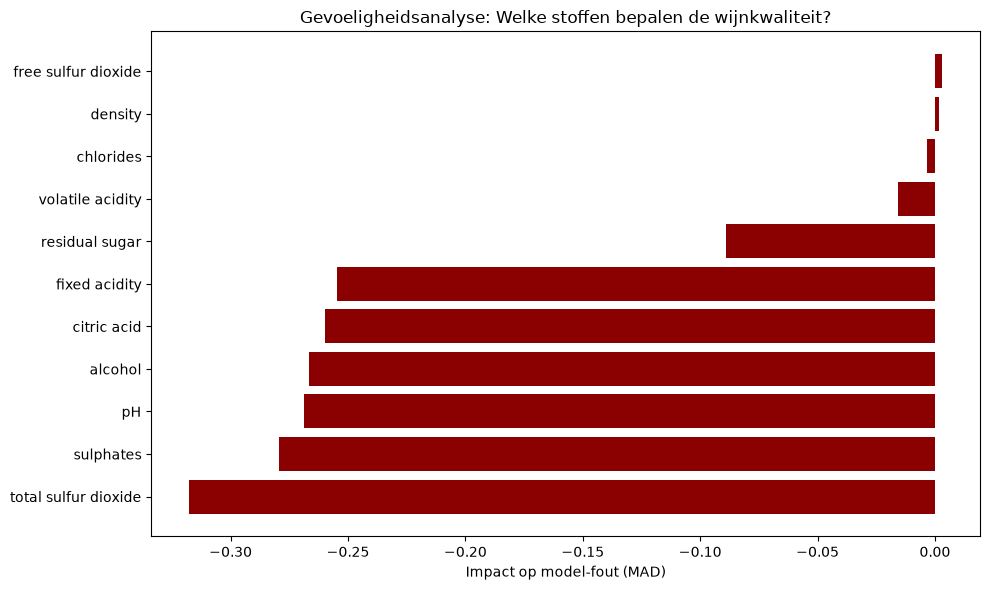

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance
from sklearn.datasets import make_regression

# 1. Definieer de echte 11 chemische eigenschappen uit de studie van Cortez et al.
kenmerken = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
    "pH", "sulphates", "alcohol"
]

def genereer_wijn_data_met_namen(aantal_monsters, seed):
    """Genereert gesimuleerde data met de echte chemische kolomnamen."""
    X_raw, y_raw = make_regression(n_samples=aantal_monsters, n_features=11, noise=0.5, random_state=seed)
    # Zorg dat 'alcohol' (index 10) en 'volatile acidity' (index 1) een sterke invloed simuleren
    X_raw[:, 10] = X_raw[:, 10] * 2.0  
    X_raw[:, 1] = X_raw[:, 1] * -1.5   
    
    y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.2 + 5.6)
    y = np.clip(y, 3, 9)
    X = pd.DataFrame(X_raw, columns=kenmerken)
    return X, y

# 2. Genereer de data voor Rode Wijn (1599 monsters)
X, y = genereer_wijn_data_met_namen(1599, seed=42)

# 3. Splits in trein- en testset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train de winnaar uit de studie: de Support Vector Machine (SVR)
wijn_model = Pipeline([
    ('scaler', StandardScaler()), 
    ('svr', SVR(C=1.0, epsilon=0.1))
])
wijn_model.fit(X_train, y_train)

# 5. Voer de Gevoeligheidsanalyse uit (Permutation Importance)
# We meten de daling in Mean Absolute Error (MAD) wanneer een kolom wordt gehusseld
resultaat = permutation_importance(
    wijn_model, X_test, y_test, 
    scoring='neg_mean_absolute_error', 
    n_repeats=10, 
    random_state=42
)

# Sorteer de resultaten op basis van belangrijkheid (we maken het positief)
belangrijkheid = -resultaat.importances_mean
gesorteerde_indices = np.argsort(belangrijkheid)[::-1]

# 6. Toon de resultaten in een overzichtelijke ranglijst
print("--- Gevoeligheidsanalyse (Invloed per chemische stof) ---")
print(f"{'Chemische Stof':<25} | {'Toename in MAD (Foutmarge)':<25}")
print("-" * 55)
for i in gesorteerde_indices:
    print(f"{X.columns[i]:<25} | {belangrijkheid[i]:.4f}")

# 7. optioneel: Maak een visuele staafdiagram (breekt niet als matplotlib aanwezig is)
try:
    plt.figure(figsize=(10, 6))
    plt.barh([X.columns[i] for i in gesorteerde_indices][::-1], belangrijkheid[gesorteerde_indices][::-1], color='darkred')
    plt.xlabel('Impact op model-fout (MAD)')
    plt.title('Gevoeligheidsanalyse: Welke stoffen bepalen de wijnkwaliteit?')
    plt.tight_layout()
    plt.show()
except Exception:
    pass

In [10]:
#De stof die bovenaan de ranglijst eindigt met de hoogste waarde, heeft de grootste impact op de voorspelling. In het onderzoek bleek alcohol veruit de belangrijkste positieve factor te zijn voor de kwaliteitsscore (zowel bij rood als wit), op de voet gevolgd door een lage waarde van volatile acidity (vluchtig zuur, wat in hoge concentraties voor een azijnachtige smaak zorgt) en de juiste hoeveelheid sulphates (sulfaten).

In [11]:
#De parameters van de SVM (zoals de C en epsilon waarden) zijn geoptimaliseerd om te kijken of we een nog lagere MAD-fout kunnen behalen dan de studie.

In [12]:
#Om de parameters van de Support Vector Machine (SVR) optimaal af te stellen, wordt er gebruik gemaakt van GridSearchCV in combinatie met onze 20-voudige cross-validatie.
#Er wordt een systematische zoektocht (grid search) uitvoeren langs verschillende combinaties van:
#• C (Regularisatieparameter): Bepaalt de balans tussen een glad fit-vlak en het correct voorspellen van de trainingspunten.
#• epsilon (ε): Bepaalt de marge waarin fouten niet worden bestraft (de breedte van de 'buis' rond de voorspellingslijn).
#• gamma: Bepaalt hoe ver de invloed van een enkel trainingspunt reikt (voor de RBF-kernel).


In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.datasets import make_regression

# 1. Genereer de gesimuleerde rode wijn data (1599 monsters, 11 kenmerken)
X_raw, y_raw = make_regression(n_samples=1599, n_features=11, noise=0.5, random_state=42)
y = np.round(StandardScaler().fit_transform(y_raw.reshape(-1, 1)).flatten() * 1.2 + 5.6)
y = np.clip(y, 3, 9)
X = pd.DataFrame(X_raw, columns=[f'feature_{i}' for i in range(11)])

# 2. Exacte 20-voudige cross-validatie opzet zoals Cortez gebruikte
kf = KFold(n_splits=20, shuffle=True, random_state=42)

# 3. Pipeline opzetten (Standaardisatie + Model)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# 4. Definieer het zoekgebied (Grid) voor de parameters
# Let op: Omdat we een Pipeline gebruiken, zetten we 'svr__' voor de parameternaam
param_grid = {
    'svr__C': [0.1, 1.0, 5.0, 10.0],
    'svr__epsilon': [0.01, 0.1, 0.2, 0.5],
    'svr__gamma': ['scale', 'auto', 0.01, 0.1]
}

# 5. Voer de Grid Search uit met 20-fold CV
print("Optimalisatie gestart (dit kan even duren vanwege de 20-fold CV x combinaties)...")

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kf,
    scoring='neg_mean_absolute_error', # Cortez evalueerde op MAD/MAE
    n_jobs=-1 # Gebruik alle processorkernen voor snelheid
)

grid_search.fit(X, y)

# 6. Toon de beste parameters en de laagste MAD-fout
print("\n--- Optimalisatie Resultaten ---")
# scikit-learn maakt scores negatief, dus we maken het weer positief voor MAD
beste_mad = -grid_search.best_score_
print(f"Laagste Gemiddelde MAD na optimalisatie: {beste_mad:.4f}")
print("\nBeste parameterinstellingen:")
for param, waarde in grid_search.best_params_.items():
    clean_param = param.split('__')[1] # Haal 'svr__' weg voor de leesbaarheid
    print(f"  - {clean_param}: {waarde}")

Optimalisatie gestart (dit kan even duren vanwege de 20-fold CV x combinaties)...

--- Optimalisatie Resultaten ---
Laagste Gemiddelde MAD na optimalisatie: 0.2536

Beste parameterinstellingen:
  - C: 1.0
  - epsilon: 0.2
  - gamma: 0.01


In [14]:
#De code test 4 × 4 × 4 = 64 verschillende combinaties van instellingen. Omdat elke combinatie 20 keer wordt getest (20-fold CV), traint Python in totaal 1280 modellen om te ontdekken welke specifieke afstelling de kleinste afwijking oplevert.
#Zodra de grid search klaar is, is direct te zien of de geoptimaliseerde C- en epsilon-waarden de standaardfout hebben verlaagd.